# Fitness club users: EDA and segmentation

Training case project. Exploratory analysis of the users table and segmentation of users by activity.

**Tools:** Python (Pandas, NumPy, Matplotlib, Seaborn)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
users_info = pd.read_csv('users_info.csv')
users_info.head()

,id_user,city,age,gender
0,1000,СПб,44.0,female
1,1001,Москва,35.0,female
2,1002,Москва,34.0,male
3,1003,Москва,NaN,NaN
4,1004,Екатеринбург,60.0,male


## Task 1. Exploratory data analysis (EDA)

In [ ]:
print('Shape (rows, columns):', users_info.shape)
print()
print(users_info.dtypes)

Shape (rows, columns): (1000, 4)

id_user      int64
city        object
age        float64
gender      object
dtype: object


In [ ]:
# Missing values per column (before removing anything)
users_info.isnull().sum()

,0
id_user,0
city,0
age,88
gender,89


In [ ]:
# Remove all rows with missing values and check how much data was removed
rows_before = len(users_info)
users_info = users_info.dropna()
rows_after = len(users_info)
removed = rows_before - rows_after
print(f"Removed {removed} rows ({removed / rows_before:.1%}), left {rows_after}")

Removed 135 rows (13.5%), left 865


In [ ]:
# Outliers in age: IQR method
users_info['age'].describe()

,age
count,865.000000
mean,39.419653
std,13.774501
min,18.000000
25%,28.000000
50%,37.000000
75%,51.000000
max,65.000000


In [ ]:
Q1 = np.percentile(users_info['age'], 25)
Q3 = np.percentile(users_info['age'], 75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print('Outlier bounds:', lower_bound, upper_bound)

Outlier bounds: -6.5 85.5


In [ ]:
mask = users_info['age'].between(lower_bound, upper_bound)
print(f"Outliers removed: {(~mask).sum()}, remaining: {mask.sum()}")
ui_clean = users_info[mask]
ui_clean.head()

Outliers removed: 0, remaining: 865


,id_user,city,age,gender
0,1000,СПб,44.0,female
1,1001,Москва,35.0,female
2,1002,Москва,34.0,male
4,1004,Екатеринбург,60.0,male
5,1005,СПб,35.0,female


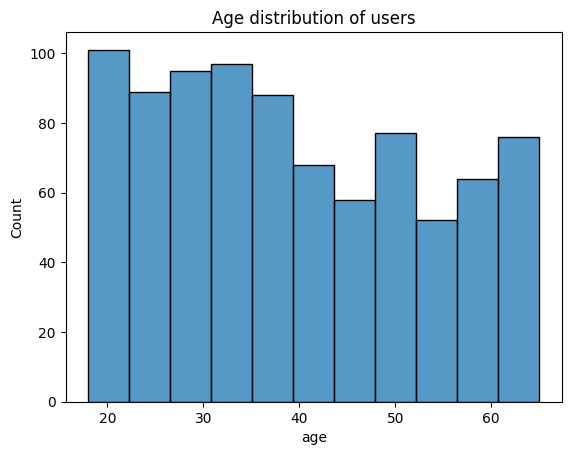

In [ ]:
sns.histplot(ui_clean['age'])
plt.title('Age distribution of users')
plt.show()

## Task 2. Share of female users by city

In [ ]:
grouped = ui_clean.groupby(['city', 'gender']).size().unstack(fill_value=0)
print(grouped)

gender        female  male
city                      
Екатеринбург      55    78
Казань            53    77
Москва           220   105
СПб              123   154


In [ ]:
pivot = pd.pivot_table(ui_clean,
                       values='id_user',
                       index='city',
                       columns='gender',
                       aggfunc='count',
                       fill_value=0).reset_index()
pivot

gender,city,female,male
0,Екатеринбург,55,78
1,Казань,53,77
2,Москва,220,105
3,СПб,123,154


In [ ]:
pivot['total'] = pivot['female'] + pivot['male']
pivot['female_ratio'] = pivot['female'] / pivot['total'] * 100
print(pivot[['city', 'female_ratio']])

gender          city  female_ratio
0       Екатеринбург     41.353383
1             Казань     40.769231
2             Москва     67.692308
3                СПб     44.404332


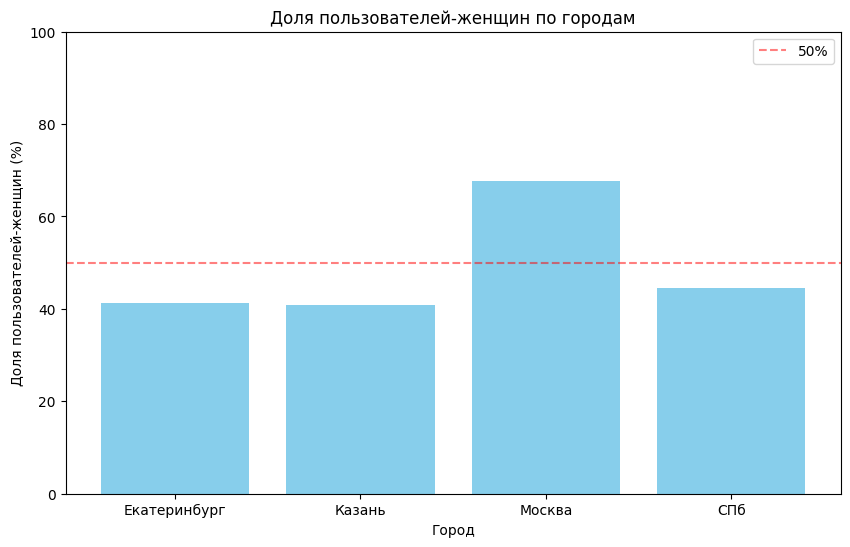

In [ ]:
plt.figure(figsize=(10, 6))
plt.bar(pivot['city'], pivot['female_ratio'], color='skyblue')
plt.xlabel('Город')
plt.ylabel('Доля пользователей-женщин (%)')
plt.title('Доля пользователей-женщин по городам')
plt.ylim(0, 100)
plt.axhline(y=50, color='red', linestyle='--', alpha=0.5, label='50%')
plt.legend()
plt.show()

## Task 3. Segmentation by number of workouts

In [ ]:
pay_mon = pd.read_csv('payments_monthly.csv')

user_avg_cnt = pay_mon.groupby('id_user')['cnt_total'].mean().reset_index()
user_avg_cnt.columns = ['id_user', 'avg_cnt_total']
user_avg_cnt.head()

,id_user,avg_cnt_total
0,1000,3.666667
1,1001,11.727273
2,1002,11.636364
3,1003,5.166667
4,1004,2.000000


In [ ]:
# Three groups of roughly equal size: boundaries are the 1/3 and 2/3 quantiles
q1, q2 = user_avg_cnt['avg_cnt_total'].quantile([1/3, 2/3])
print('Group boundaries:', q1, q2)

user_avg_cnt['activity_group'] = pd.cut(
    user_avg_cnt['avg_cnt_total'],
    bins=[-np.inf, q1, q2, np.inf],
    labels=['мало', 'средне', 'много']
)
user_avg_cnt['activity_group'].value_counts()

Group boundaries: 4.0 7.347222222222214


,count
activity_group,
мало,336
много,323
средне,310


## Findings

In [ ]:
print(f"Rows removed because of missing values: {removed} ({removed / rows_before:.1%})")
print(f"Age outliers removed: {(~mask).sum()}; age range: {ui_clean['age'].min():.0f}-{ui_clean['age'].max():.0f}")
top = pivot.loc[pivot['female_ratio'].idxmax()]
print(f"Highest share of female users: {top['city']} ({top['female_ratio']:.1f}%)")
print()
print('Users by activity group:')
print(user_avg_cnt['activity_group'].value_counts())

Rows removed because of missing values: 135 (13.5%)
Age outliers removed: 0; age range: 18-65
Highest share of female users: Москва (67.7%)

Users by activity group:
activity_group
мало      336
много     323
средне    310
Name: count, dtype: int64
